# Notebook 01: Data Understanding and Exploratory Data Analysis

**Purpose.** Learn what the dataset really contains before making any modelling decision. Clustering depends entirely on the input features and on the geometry of the data, so this notebook asks three questions:

1. Is the data clean and consistent?
2. How is each variable distributed?
3. Do variables relate to each other in a way that could produce natural groups of users?

**A note on the data.** The dataset is synthetic and comes without a data dictionary, so column meanings below are inferred from names and values. Where a meaning is uncertain, the text says so. The original file name mentions Spotify, but this is simulated data and says nothing about real Spotify users.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from IPython.display import display

from src.data_loader import ensure_output_dirs, load_config, load_raw_data, project_path
from src.evaluation import cramers_v, eta_squared
from src.preprocessing import add_tenure_months, find_logical_inconsistencies, iqr_outlier_summary
from src.visualization import (
    apply_plot_style,
    plot_association_heatmap,
    plot_box_by_group,
    plot_boxplots,
    plot_category_frequencies,
    plot_numeric_histograms,
    plot_relationship_panels,
    save_figure,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

config = load_config()
ensure_output_dirs(config)
apply_plot_style()
METRICS_DIR = project_path(config["paths"]["metrics_dir"])
SEED = config["random_seed"]

## A. Load the dataset

`signup_date` is parsed as a date when the file is loaded, because a date stored as text cannot be used for time calculations.

In [2]:
df = load_raw_data(config)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print("Column names:", list(df.columns))

Rows: 50,000   Columns: 18
Column names: ['user_id', 'country', 'age', 'signup_date', 'subscription_type', 'subscription_status', 'months_inactive', 'inactive_3_months_flag', 'ad_interaction', 'ad_conversion_to_subscription', 'music_suggestion_rating_1_to_5', 'avg_listening_hours_per_week', 'favorite_genre', 'most_liked_feature', 'desired_future_feature', 'primary_device', 'playlists_created', 'avg_skips_per_day']


In [3]:
display(df.head())
display(df.tail())

,user_id,country,age,signup_date,subscription_type,subscription_status,months_inactive,inactive_3_months_flag,ad_interaction,ad_conversion_to_subscription,music_suggestion_rating_1_to_5,avg_listening_hours_per_week,favorite_genre,most_liked_feature,desired_future_feature,primary_device,playlists_created,avg_skips_per_day
0,1,France,25,2021-08-19,Premium Duo,Active,0,0,No,No,4,10.13,Bollywood,Radio,Concert Alerts,Tablet,7,8
1,2,Indonesia,20,2022-06-06,Premium Family,Active,0,0,Yes,No,5,11.63,Latin,Podcasts,Lyrics Translation,Mobile,7,6
2,3,Italy,53,2024-01-04,Premium Individual,Active,0,0,Yes,Yes,3,9.50,Bollywood,Lyrics,Better AI Recommendations,Desktop,6,5
3,4,Italy,48,2018-08-26,Premium Individual,Active,1,0,No,No,4,13.16,Electronic,Playlists,Social Listening,Smart Speaker,11,8
4,5,Australia,18,2020-05-29,Free,Active,0,0,No,No,4,12.70,Indie,Daily Mix,Lyrics Translation,Tablet,10,11


,user_id,country,age,signup_date,subscription_type,subscription_status,months_inactive,inactive_3_months_flag,ad_interaction,ad_conversion_to_subscription,music_suggestion_rating_1_to_5,avg_listening_hours_per_week,favorite_genre,most_liked_feature,desired_future_feature,primary_device,playlists_created,avg_skips_per_day
49995,49996,India,33,2022-09-23,Free,Active,2,0,Yes,No,5,11.83,Latin,Offline Mode,Concert Alerts,Tablet,8,5
49996,49997,Italy,35,2023-11-17,Premium Family,Active,0,0,No,No,4,8.01,Latin,Podcasts,Mood-based Auto Playlists,Car System,11,10
49997,49998,Brazil,33,2024-11-14,Premium Individual,Active,0,0,No,No,2,14.47,Rock,Lyrics,Lyrics Translation,Smart Speaker,9,13
49998,49999,USA,43,2021-05-31,Free,Active,0,0,No,No,5,21.86,Indie,AI DJ,Social Listening,Mobile,9,12
49999,50000,Indonesia,38,2024-07-05,Free,Inactive,3,1,No,No,5,13.30,Rock,Podcasts,Better AI Recommendations,Tablet,9,12


In [4]:
overview = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "unique_values": df.nunique(),
        "missing_values": df.isna().sum(),
        "example": df.iloc[0].astype(str),
    }
)
overview

,dtype,unique_values,missing_values,example
user_id,int64,50000,0,1
country,str,12,0,France
age,int64,45,0,25
signup_date,datetime64[us],2982,0,2021-08-19 00:00:00
subscription_type,str,5,0,Premium Duo
subscription_status,str,2,0,Active
months_inactive,int64,19,0,0
inactive_3_months_flag,int64,2,0,0
ad_interaction,str,2,0,No
ad_conversion_to_subscription,str,2,0,No


**What we see.** The file holds 50,000 users and 18 columns: 8 numeric, 9 text and 1 date. `user_id` is a plain row counter.

**Difference from the project brief.** The brief mentioned possible `engaging_score` and `engaging_level` columns. They are not in this file, so no later step uses them.

## B. Data quality analysis

We check, in order: missing values, duplicates, valid ranges, unexpected categories, constant columns and potential outliers. Then we go one step further and test whether **different columns agree with each other**, because a table can look clean column by column and still contain combinations that make no sense.

In [5]:
print("Missing values in the whole table:", int(df.isna().sum().sum()))
print("Fully duplicated rows:", int(df.duplicated().sum()))
print("Duplicated rows ignoring user_id:", int(df.drop(columns="user_id").duplicated().sum()))
print("user_id unique:", df["user_id"].is_unique, f"(from {df['user_id'].min()} to {df['user_id'].max()})")

text_columns = df.select_dtypes(exclude=["number", "datetime"]).columns
stray_spaces = {column: int((df[column] != df[column].str.strip()).sum()) for column in text_columns}
case_variants = {column: df[column].nunique() - df[column].str.lower().nunique() for column in text_columns}
print("Values with stray spaces:", sum(stray_spaces.values()))
print("Categories differing only by letter case:", sum(case_variants.values()))

constant_columns = [column for column in df.columns if df[column].nunique() == 1]
print("Columns with a single value (zero variance):", constant_columns)
print("Signup dates:", df["signup_date"].min().date(), "to", df["signup_date"].max().date())

Missing values in the whole table: 0
Fully duplicated rows: 0
Duplicated rows ignoring user_id: 0
user_id unique: True (from 1 to 50000)


Values with stray spaces: 0
Categories differing only by letter case: 0
Columns with a single value (zero variance): []
Signup dates: 2018-01-01 to 2026-03-01


In [6]:
numeric_columns = [
    "age",
    "months_inactive",
    "music_suggestion_rating_1_to_5",
    "avg_listening_hours_per_week",
    "playlists_created",
    "avg_skips_per_day",
]
numeric_stats = df[numeric_columns].describe().T
numeric_stats["skewness"] = df[numeric_columns].skew()
numeric_stats["share_zero"] = (df[numeric_columns] == 0).mean()
numeric_stats.to_csv(METRICS_DIR / "eda_numeric_summary.csv")
numeric_stats.round(3)

,count,mean,std,min,25%,50%,75%,max,skewness,share_zero
age,50000.0,38.010,12.985,16.0,27.00,38.00,49.00,60.00,-0.006,0.000
months_inactive,50000.0,1.533,1.952,0.0,0.00,1.00,2.00,18.00,1.984,0.392
music_suggestion_rating_1_to_5,50000.0,3.644,1.114,1.0,3.00,4.00,5.00,5.00,-0.598,0.000
avg_listening_hours_per_week,50000.0,9.989,3.969,0.0,7.28,9.98,12.68,26.25,0.032,0.007
playlists_created,50000.0,8.003,2.832,0.0,6.00,8.00,10.00,23.00,0.355,0.000
avg_skips_per_day,50000.0,10.026,3.166,1.0,8.00,10.00,12.00,25.00,0.314,0.000


### Logical consistency between columns

Each rule below expresses what we would *expect* if a column means what its name suggests. A hit is therefore a question about the data, not automatically an error. Tenure is measured up to the latest signup date in the file, which is itself an assumption because no snapshot date is documented.

In [7]:
df_with_tenure = add_tenure_months(df)
inconsistencies = find_logical_inconsistencies(df_with_tenure)
inconsistencies.to_csv(METRICS_DIR / "eda_logical_inconsistencies.csv", index=False)
inconsistencies

,check,rows,percent_of_users,affects_clustering_inputs
0,Zero listening hours but at least one skip per...,327,0.65,Yes: both are clustering features
1,Status 'Active' with 3+ months inactive,3232,6.46,No: outcome-related columns
2,Converted from an ad but still on the Free plan,1921,3.84,No: interpretation columns
3,Paid plan but interacted with an ad,9647,19.29,No: interpretation column
4,Student plan at age 30 or older,3099,6.20,No: interpretation columns
5,Months inactive exceeds account tenure,854,1.71,No: outcome-related column


**Column by column, the data is very clean:** no missing values, no duplicates, no stray spaces or spelling variants, no constant columns, and every value is in a plausible range.

**Across columns, some combinations look odd:**

- 327 users (0.65%) have exactly zero listening hours but still skip at least once per day.
- 3,232 users (6.46%) are `Active` despite 3 or more months of inactivity.
- 1,921 users (3.84%) are marked as converted to a subscription yet are on the Free plan.
- 9,647 users (19.29%) on paid plans interacted with ads, which may be fine if paid plans still show some ads.
- 3,099 users (6.20%) on the Student plan are 30 or older, which is possible but not typical.
- 854 users (1.71%) have been inactive for longer than their measured tenure, though this depends on the assumed snapshot date.

These patterns suggest that columns were generated largely independently rather than by simulating coherent users. Without a data dictionary we cannot call them errors, so **no rows are removed because of them**. Only the first one touches clustering inputs, and Notebook 05 tests its effect.

## C. Numerical feature analysis

Histograms show the shape of each distribution. Boxplots show the spread and the values flagged as potential outliers by the standard 1.5 x IQR rule.

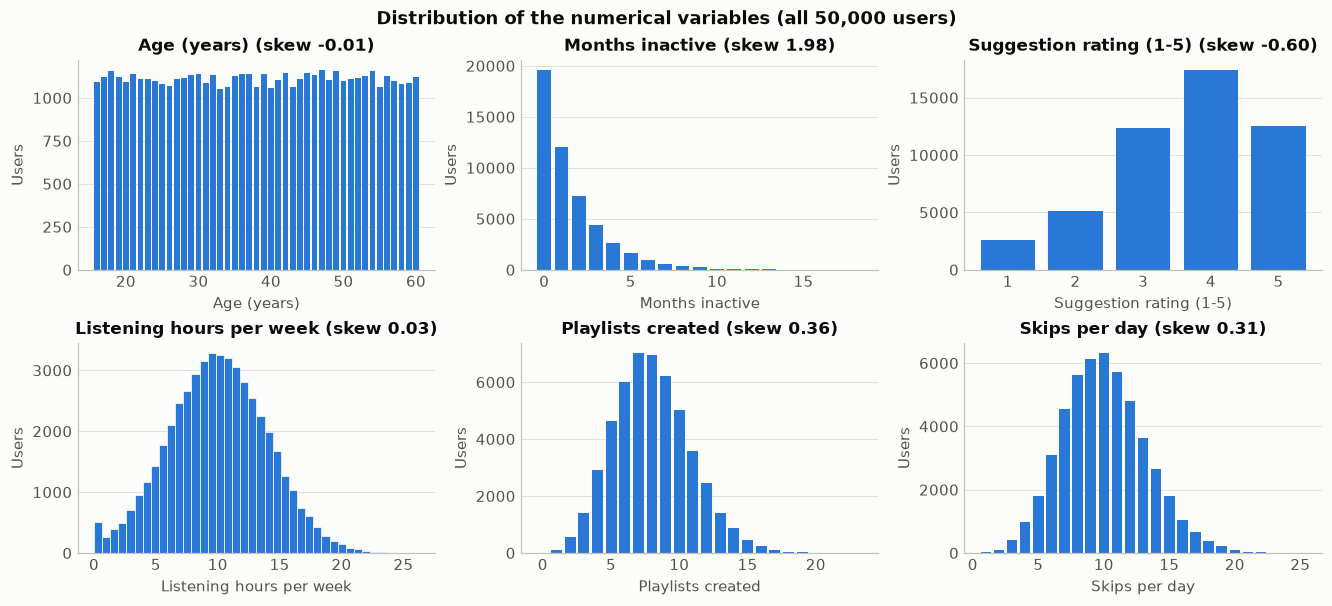

In [8]:
fig = plot_numeric_histograms(df, numeric_columns, "Distribution of the numerical variables (all 50,000 users)")
save_figure(fig, "eda_numeric_distributions", config)

,feature,lower_fence,upper_fence,min,max,outliers,percent
0,age,-6.00,82.00,16.0,60.00,0,0.00
1,months_inactive,-3.00,5.00,0.0,18.00,2417,4.83
2,music_suggestion_rating_1_to_5,0.00,8.00,1.0,5.00,0,0.00
3,avg_listening_hours_per_week,-0.82,20.78,0.0,26.25,166,0.33
4,playlists_created,0.00,16.00,0.0,23.00,185,0.37
5,avg_skips_per_day,2.00,18.00,1.0,25.00,413,0.83


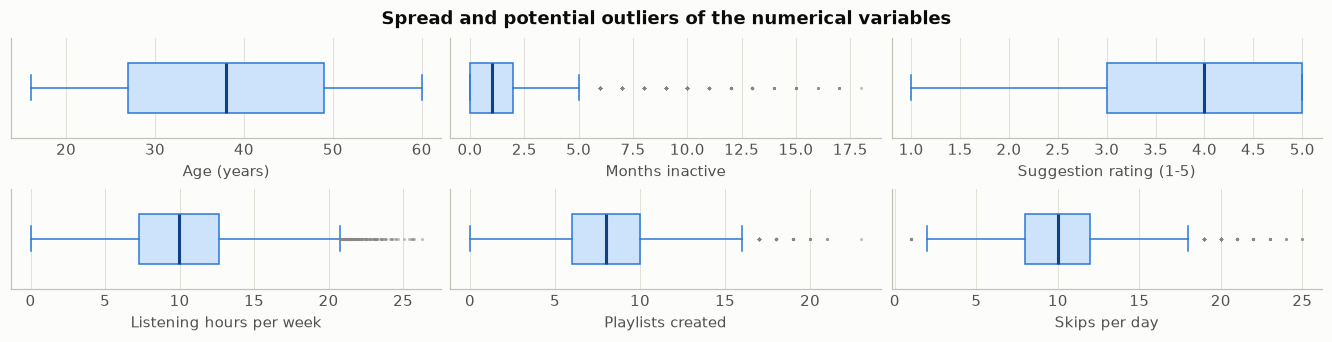

In [9]:
fig = plot_boxplots(df, numeric_columns, "Spread and potential outliers of the numerical variables")
save_figure(fig, "eda_numeric_boxplots", config)
iqr_outlier_summary(df, numeric_columns).round(2)

### Are the count variables Poisson-like?

For a Poisson count, the variance equals the mean. A ratio close to 1 is what a simple counting simulation would produce, which helps us understand how the data was probably generated.

In [10]:
for column in ["playlists_created", "avg_skips_per_day"]:
    print(f"{column}: mean {df[column].mean():.3f}, variance {df[column].var():.3f}, ratio {df[column].var() / df[column].mean():.3f}")
print("Users with exactly 0 listening hours:", int((df["avg_listening_hours_per_week"] == 0).sum()))

playlists_created: mean 8.003, variance 8.018, ratio 1.002
avg_skips_per_day: mean 10.026, variance 10.021, ratio 0.999
Users with exactly 0 listening hours: 327


**Distributions.**

- **Listening hours** form a symmetric bell shape around 10 hours (skew 0.03). The small spike at 0 is 327 users, and it looks like values below zero were clipped.
- **Playlists and skips** have a variance almost exactly equal to their mean (ratios 1.002 and 0.999), which is the signature of a Poisson count. Their slight right skew (0.36 and 0.31) is normal for Poisson data.
- **Suggestion rating** has five levels and leans towards high scores (skew -0.60).
- **Age** is roughly uniform between 16 and 60.
- **Months inactive** is the only strongly skewed variable (skew 1.98).

**Outliers.** Among the behavioural features, the IQR rule flags under 1% of users each (166 for hours, 185 for playlists, 413 for skips, 0 for rating). The largest values (26.25 hours per week, 23 playlists, 25 skips per day) are unusual but believable.

**Why this matters.** Every behavioural feature has **one peak**. Well-separated user groups would often show up as two or more peaks, though the absence of multiple peaks alone does not rule out groups that differ across combinations of features. Section E checks those combinations.

## D. Categorical feature analysis

We look for rare categories (which could create tiny clusters), high cardinality (which would inflate one-hot encoding), and redundancy between variables.

In [11]:
categorical_columns = [
    "subscription_type",
    "subscription_status",
    "ad_interaction",
    "ad_conversion_to_subscription",
    "country",
    "favorite_genre",
    "most_liked_feature",
    "desired_future_feature",
    "primary_device",
]
category_summary = pd.DataFrame(
    {
        "categories": df[categorical_columns].nunique(),
        "most_common_percent": (df[categorical_columns].apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1),
        "rarest_percent": (df[categorical_columns].apply(lambda s: s.value_counts(normalize=True).iloc[-1]) * 100).round(1),
    }
)
category_summary

,categories,most_common_percent,rarest_percent
subscription_type,5,45.1,8.9
subscription_status,2,84.2,15.8
ad_interaction,2,65.0,35.0
ad_conversion_to_subscription,2,91.3,8.7
country,12,8.5,8.2
favorite_genre,12,8.5,8.2
most_liked_feature,8,12.7,12.4
desired_future_feature,6,16.8,16.5
primary_device,5,20.1,19.9


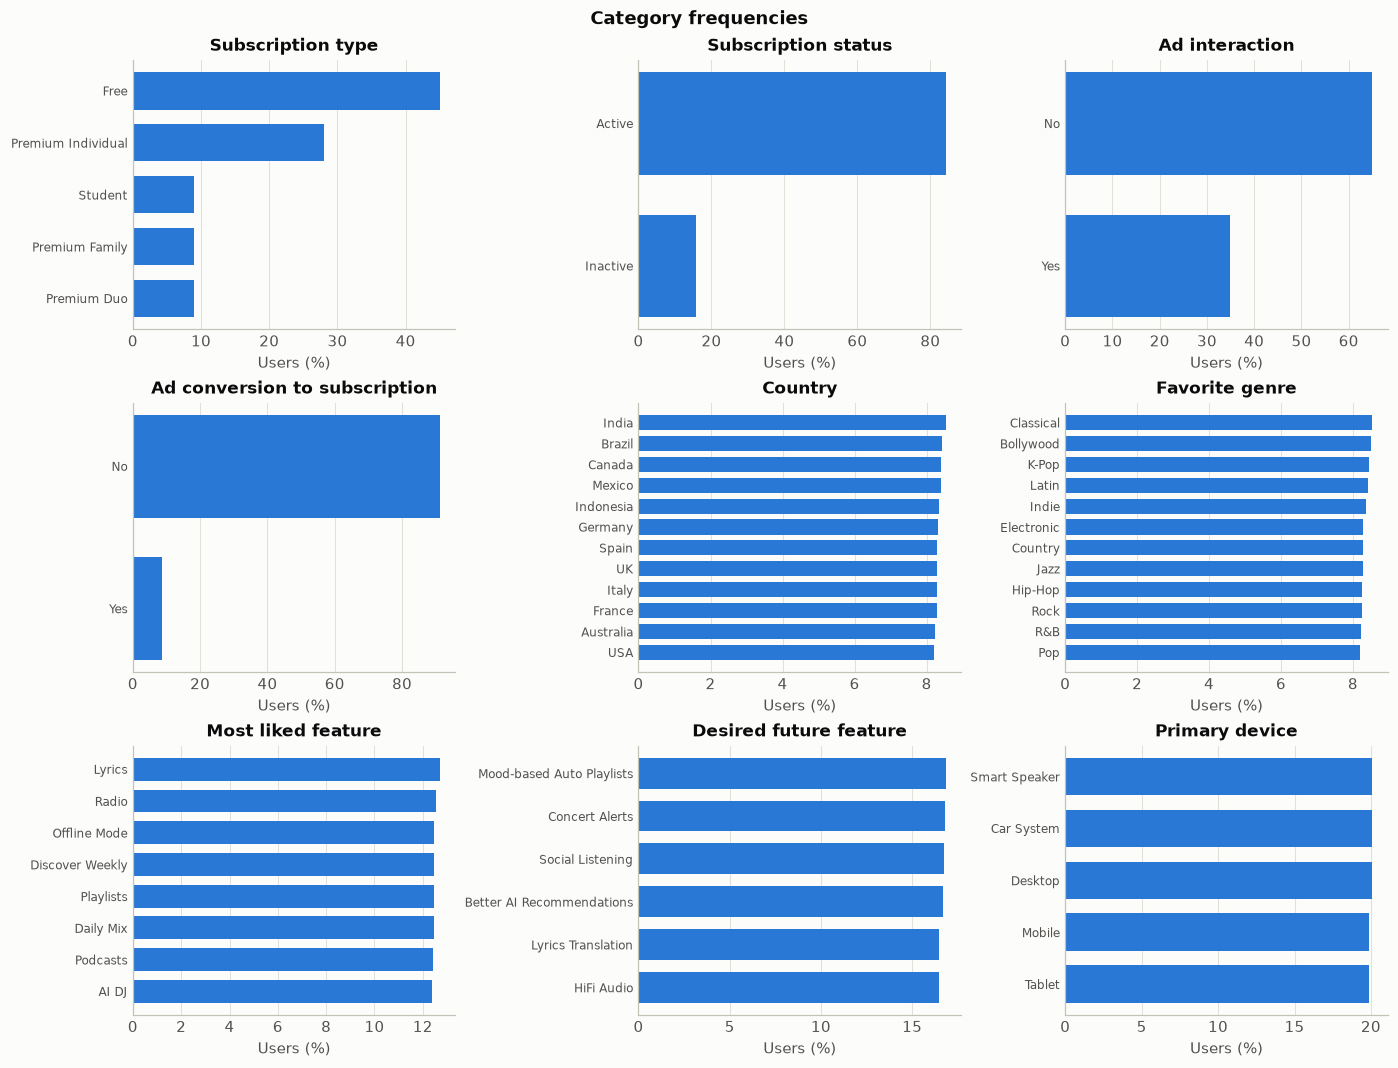

In [12]:
fig = plot_category_frequencies(df, categorical_columns, "Category frequencies")
save_figure(fig, "eda_categorical_frequencies", config)

**Categories.** There is no high-cardinality problem (12 levels at most) and no rare category: the smallest share in any variable is 8.2% (in `country` and `favorite_genre`). The distributions of `country`, `favorite_genre`, `most_liked_feature`, `desired_future_feature` and `primary_device` are almost perfectly uniform. Real music preferences would not usually be so even, which is another sign of the simulated origin of the data.

## E. Relationships between variables

This is the most important section for a clustering project. Natural groups of users would normally appear as **dependence between variables**: for example, people who listen a lot might also build many playlists and skip less. If the variables are independent, there is little for a clustering algorithm to discover.

### Numeric variables

Largest |r| overall: 0.816 (months_inactive and its own flag)
Largest |r| excluding the flag: 0.008


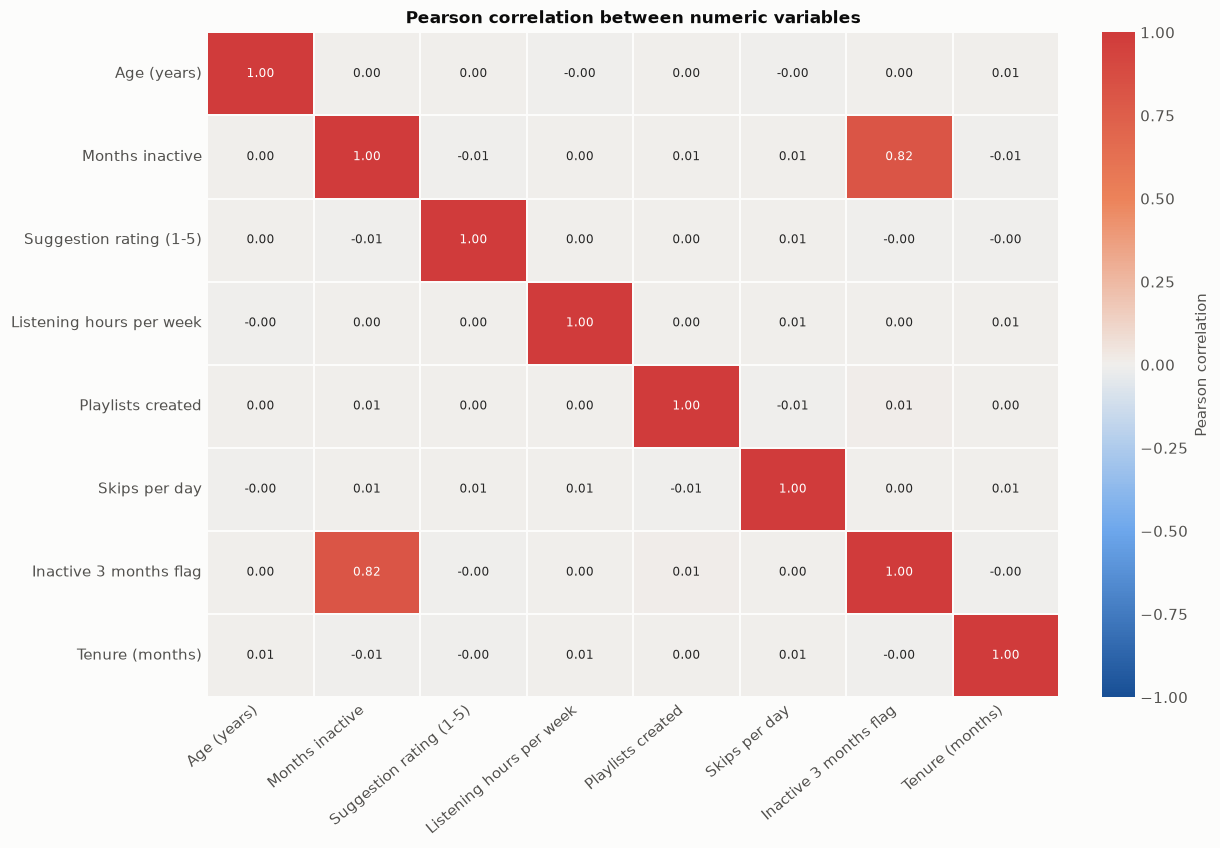

In [13]:
correlation_columns = numeric_columns + ["inactive_3_months_flag", "tenure_months"]
correlation = df_with_tenure[correlation_columns].corr()
fig = plot_association_heatmap(correlation, "Pearson correlation between numeric variables")
save_figure(fig, "eda_correlation_heatmap", config)

off_diagonal = correlation.where(~np.eye(len(correlation), dtype=bool)).stack()
without_flag = off_diagonal.drop(index="inactive_3_months_flag", level=0).drop(index="inactive_3_months_flag", level=1)
print("Largest |r| overall:", round(off_diagonal.abs().max(), 3), "(months_inactive and its own flag)")
print("Largest |r| excluding the flag:", round(without_flag.abs().max(), 3))

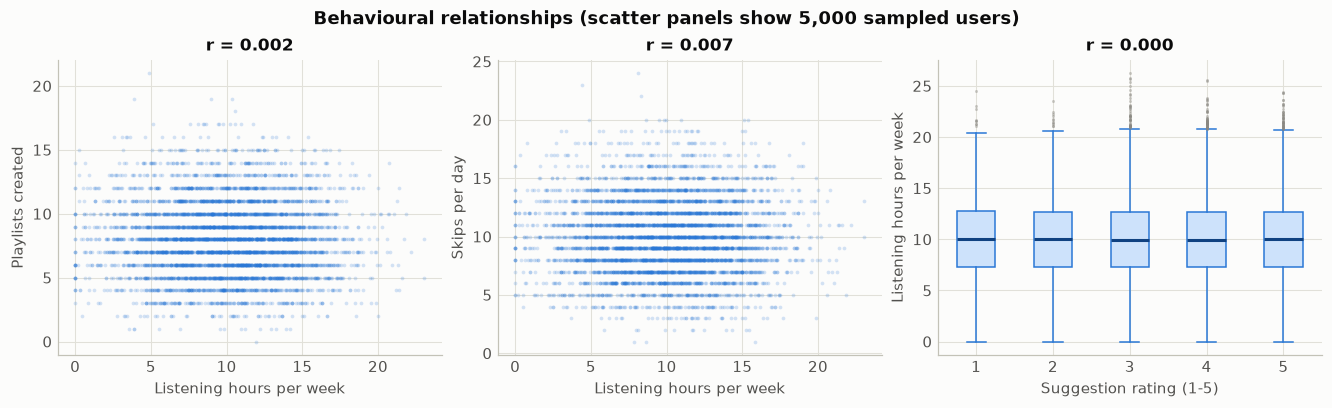

In [14]:
fig = plot_relationship_panels(df, SEED)
save_figure(fig, "eda_behaviour_relationships", config)

### Behaviour across groups

Do the users who look different on paper also behave differently? `eta squared` is the share of a numeric variable's variance explained by a group: 0 means the group tells us nothing, 1 means it tells us everything.

,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,months_inactive
subscription_status,,,,,
Active,9.99,7.99,10.02,3.65,0.98
Inactive,10.00,8.05,10.05,3.63,4.49


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5
subscription_type,,,,
Free,10.02,7.99,10.04,3.64
Premium Duo,9.96,7.95,10.07,3.63
Premium Family,9.96,8.03,10.01,3.62
Premium Individual,9.97,8.03,10.00,3.65
Student,9.95,8.01,10.01,3.66


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,age,months_inactive
subscription_type,0.0000,0.0001,0.0000,0.0001,0.0000,0.0000
subscription_status,0.0000,0.0001,0.0000,0.0000,0.0000,0.4300
ad_interaction,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
ad_conversion_to_subscription,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
country,0.0002,0.0002,0.0002,0.0002,0.0001,0.0003
favorite_genre,0.0002,0.0002,0.0001,0.0002,0.0003,0.0001
most_liked_feature,0.0003,0.0000,0.0002,0.0003,0.0001,0.0002
desired_future_feature,0.0001,0.0000,0.0000,0.0001,0.0001,0.0001
primary_device,0.0001,0.0000,0.0002,0.0001,0.0001,0.0000


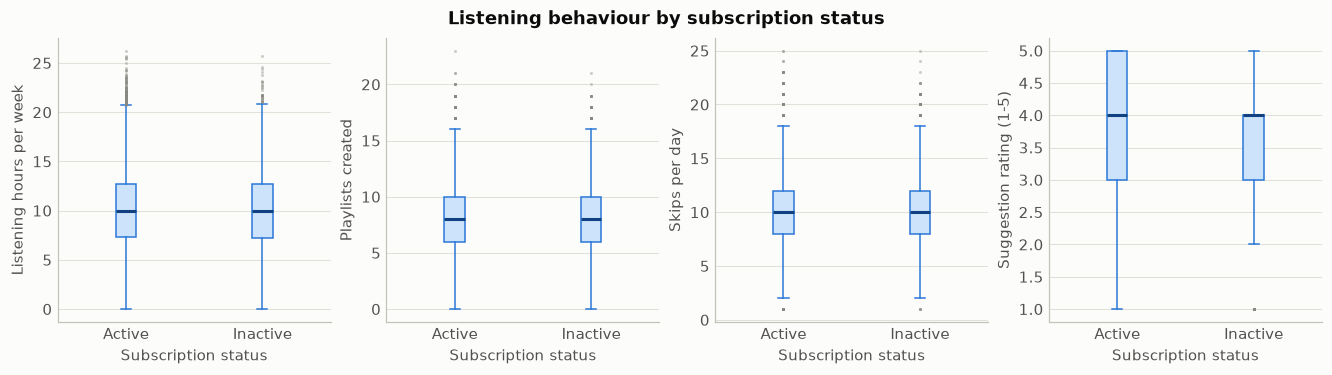

In [15]:
behaviour_columns = [
    "avg_listening_hours_per_week",
    "playlists_created",
    "avg_skips_per_day",
    "music_suggestion_rating_1_to_5",
]
fig = plot_box_by_group(df, "subscription_status", behaviour_columns, "Listening behaviour by subscription status")
save_figure(fig, "eda_behaviour_by_status", config)
display(df.groupby("subscription_status")[behaviour_columns + ["months_inactive"]].mean().round(2))
display(df.groupby("subscription_type")[behaviour_columns].mean().round(2))

eta_table = pd.DataFrame(
    {
        numeric: {group: eta_squared(df[numeric], df[group]) for group in categorical_columns}
        for numeric in behaviour_columns + ["age", "months_inactive"]
    }
)
eta_table.round(4)

### Categorical variables

Cramér's V measures association between two categorical variables, from 0 (none) to 1 (perfect). It is used rather than a p-value because, with 50,000 rows, even a tiny association can be statistically significant.

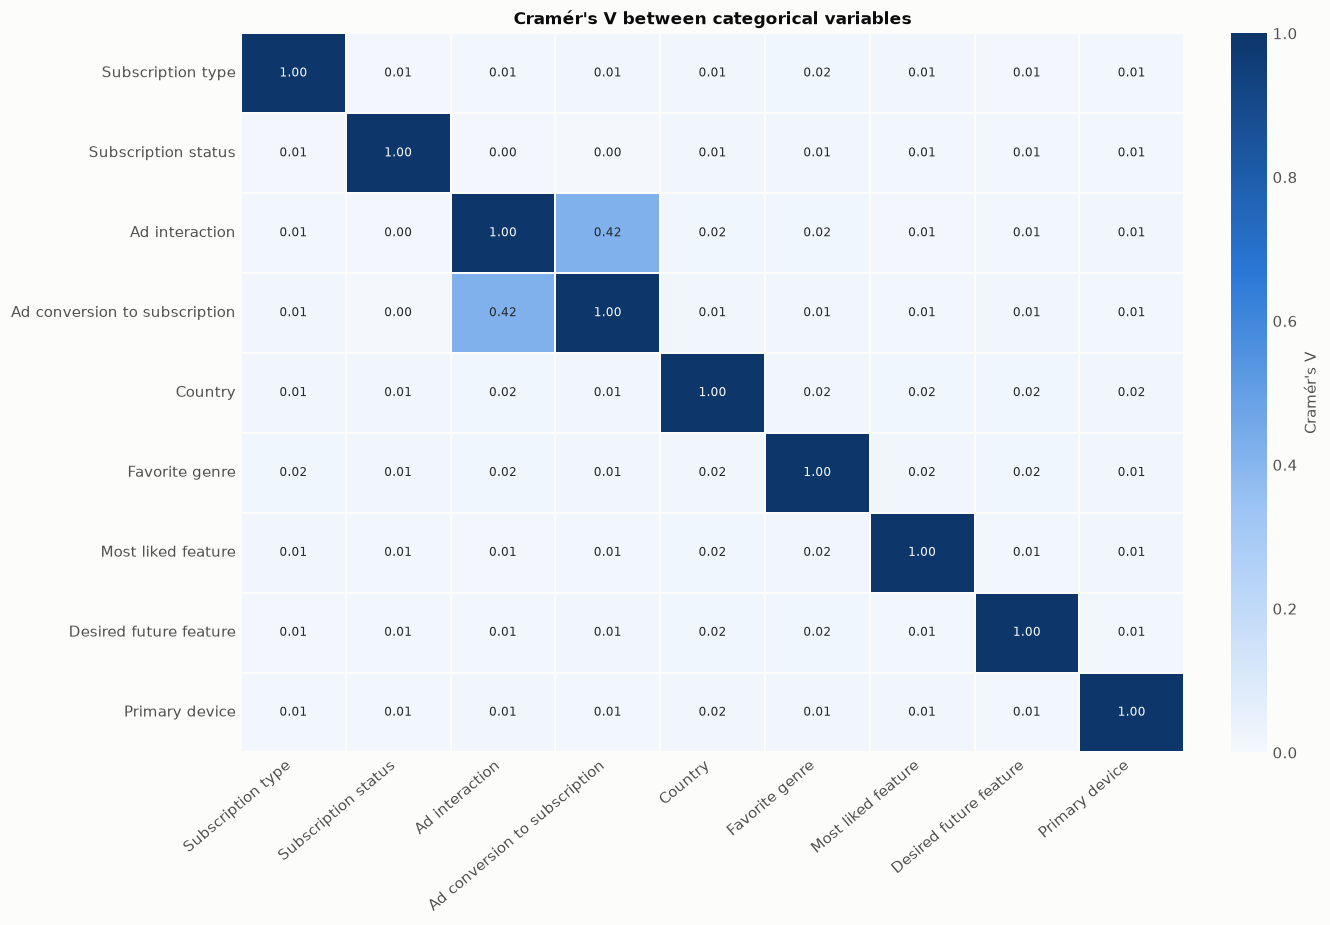

In [16]:
cramers_table = pd.DataFrame(
    {a: {b: cramers_v(df[a], df[b]) for b in categorical_columns} for a in categorical_columns}
)
fig = plot_association_heatmap(cramers_table, "Cramér's V between categorical variables", vmin=0, vmax=1, colorbar_label="Cramér's V")
save_figure(fig, "eda_cramers_v", config)
cramers_table.to_csv(METRICS_DIR / "eda_cramers_v.csv")

### How the outcome-like columns are built

Before deciding how to treat `months_inactive`, `inactive_3_months_flag`, `subscription_status` and `ad_conversion_to_subscription`, we check how they depend on one another.

In [17]:
print("Flag equals (months_inactive >= 3) for every user:", ((df["months_inactive"] >= 3).astype(int) == df["inactive_3_months_flag"]).all())
display(pd.crosstab(df["inactive_3_months_flag"], df["subscription_status"]))
display(pd.crosstab(df["ad_interaction"], df["ad_conversion_to_subscription"]))

Flag equals (months_inactive >= 3) for every user: True


subscription_status,Active,Inactive
inactive_3_months_flag,,
0,38877,0
1,3232,7891


ad_conversion_to_subscription,No,Yes
ad_interaction,,
No,32514,0
Yes,13134,4352


**This is the key finding of the EDA: the behavioural variables are essentially independent.**

- Excluding the inactivity flag, the largest correlation between any two numeric variables is |r| = 0.008. Listening more is unrelated to creating more playlists, skipping more, or rating suggestions differently.
- Subscription plan, status, country, genre, device and survey answers explain at most 0.03% of the variance of any behavioural feature or of age (eta squared of 0.0003 or less).
- Among categorical variables, Cramér's V is 0.018 or less everywhere, with one exception below.

**The only real dependencies are structural, and they involve outcome-like columns:**

- `inactive_3_months_flag` is exactly `months_inactive >= 3` for every user.
- `Inactive` status occurs only among flagged users (7,891 of 11,123, about 71%). This is why `months_inactive` explains 43% of status variance.
- `ad_conversion_to_subscription = Yes` occurs only when `ad_interaction = Yes` (4,352 of 17,486, about 25%), which gives the Cramér's V of 0.42.

**Why this matters for clustering.** Natural clusters generally produce dependence between features: if heavy-listening playlist-builders formed a group, hours and playlists would be correlated across the population. With this level of independence, K-Means and CAH are likely to slice one continuous cloud of users rather than discover separate groups. We will not assume this: Notebooks 03 and 04 test it directly.

## F. Initial feature assessment

No data dictionary exists, so descriptions are inferred from names and values. The decision column is the working plan for Notebook 02.

In [18]:
feature_assessment = pd.DataFrame(
    [
        ("user_id", "int", "Sequential row identifier, 1 to 50,000", "Identifier", "Exclude from clustering"),
        ("country", "text", "Country (12 values)", "Excluded feature", "Demographic, not behaviour; described after clustering"),
        ("age", "int", "Age, 16 to 60", "Post-clustering interpretation", "Demographic, not behaviour; described after clustering"),
        ("signup_date", "date", "Account creation date", "Excluded feature", "Raw date not usable in distances; tenure derived for interpretation"),
        ("subscription_type", "text", "Plan (Free, Student, Premium variants)", "Post-clustering interpretation", "Commercial status, not behaviour"),
        ("subscription_status", "text", "Active or Inactive; Inactive only occurs with 3+ months inactive", "Outcome-related feature", "Exclude from clustering; test associations afterwards"),
        ("months_inactive", "int", "Months without activity (meaning inferred)", "Outcome-related feature", "Exclude: drives status and defines the flag"),
        ("inactive_3_months_flag", "int", "Equals 1 exactly when months_inactive >= 3", "Derived or redundant feature", "Exclude: exact function of months_inactive"),
        ("ad_interaction", "text", "Whether the user interacted with ads", "Post-clustering interpretation", "Precondition of the conversion outcome, so kept out of the inputs"),
        ("ad_conversion_to_subscription", "text", "Converted after an ad; only occurs after ad interaction", "Outcome-related feature", "Exclude from clustering; test associations afterwards"),
        ("music_suggestion_rating_1_to_5", "int", "Ordinal rating of music suggestions", "Candidate clustering feature", "Include in Representation A (treated as approximately interval)"),
        ("avg_listening_hours_per_week", "float", "Average weekly listening time", "Candidate clustering feature", "Include in Representation A"),
        ("favorite_genre", "text", "Favourite genre (12 values)", "Candidate clustering feature", "Representation B only (one-hot)"),
        ("most_liked_feature", "text", "Most liked product feature (8 values)", "Post-clustering interpretation", "Survey opinion, not listening behaviour"),
        ("desired_future_feature", "text", "Requested future feature (6 values)", "Post-clustering interpretation", "Survey opinion, not listening behaviour"),
        ("primary_device", "text", "Main listening device (5 values)", "Candidate clustering feature", "Representation B only (one-hot)"),
        ("playlists_created", "int", "Number of playlists created", "Candidate clustering feature", "Include in Representation A"),
        ("avg_skips_per_day", "int", "Average skips per day (rounded in the data)", "Candidate clustering feature", "Include in Representation A"),
    ],
    columns=["Feature", "Data Type", "Description", "Potential Role", "Decision"],
)
assert set(feature_assessment["Feature"]) == set(df.columns), "The table must cover every column exactly once"
feature_assessment.to_csv(METRICS_DIR / "eda_feature_assessment.csv", index=False)
pd.set_option("display.max_colwidth", 90)
feature_assessment

,Feature,Data Type,Description,Potential Role,Decision
0,user_id,int,"Sequential row identifier, 1 to 50,000",Identifier,Exclude from clustering
1,country,text,Country (12 values),Excluded feature,"Demographic, not behaviour; described after clustering"
2,age,int,"Age, 16 to 60",Post-clustering interpretation,"Demographic, not behaviour; described after clustering"
3,signup_date,date,Account creation date,Excluded feature,Raw date not usable in distances; tenure derived for interpretation
4,subscription_type,text,"Plan (Free, Student, Premium variants)",Post-clustering interpretation,"Commercial status, not behaviour"
5,subscription_status,text,Active or Inactive; Inactive only occurs with 3+ months inactive,Outcome-related feature,Exclude from clustering; test associations afterwards
6,months_inactive,int,Months without activity (meaning inferred),Outcome-related feature,Exclude: drives status and defines the flag
7,inactive_3_months_flag,int,Equals 1 exactly when months_inactive >= 3,Derived or redundant feature,Exclude: exact function of months_inactive
8,ad_interaction,text,Whether the user interacted with ads,Post-clustering interpretation,"Precondition of the conversion outcome, so kept out of the inputs"
9,ad_conversion_to_subscription,text,Converted after an ad; only occurs after ad interaction,Outcome-related feature,Exclude from clustering; test associations afterwards


**Uncertainty.** All descriptions are inferred. In particular, we do not know the time window of `months_inactive`, whether listening averages are computed before or during inactivity, or what `Inactive` status formally means. This is one more reason not to tie segments to churn.

## G. EDA conclusion

- **Data quality:** excellent per column, with no missing values or duplicates. Some cross-column combinations look implausible, so they are documented rather than removed.
- **Distributions:** behavioural features each have one peak; hours are bell-shaped, playlists and skips are Poisson-like, and ratings are discrete with a lean towards high values.
- **Candidate clustering features:** listening hours, playlists created, skips per day and suggestion rating. Genre and device are candidates for a mixed representation.
- **Preprocessing challenges:** different measurement scales and an ordinal rating feature, but no heavy skew in the selected features.
- **Limitations:** no data dictionary, synthetic origin, and near-total independence between variables. That independence is the main risk to the project, as it suggests clusters may not reflect natural groups.